Lab 4 Analysis Code

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import odr

In [21]:
data = [
    [0.5, 0.5, 0.5], [1.0, 1.0, 1.0], [1.5, 1.5, 1.5], 
    [2.0, 2.0, 2.0],[2.5, 2.5, 2.5], [3.0, 3.0, 3.0],
    [3.5, 3.5, 3.5], [4.5, 4.5, 4.5], [5.5, 5.5, 5.5], 
    [6.5, 6.5, 6.0], [7.5, 7.5, 7.5], [8.0, 8.5, 8.5], 
] # Where each sweep is a sub-list

# Convert data for N = 0  lab standard and concatenate to a single list and flip order
sweeps = [[8.5 - measurement for measurement in sublist] for sublist in data][::-1]
print(sweeps)

p_atm = 103.1 # in kPa, from montreal airport at 2pm
read_pressures = [4, 6, 8, 10, 12, 14, 16, 20, 24, 28, 32, 36] # Pressure difference in cm Hg

# Using conversion found here https://convertlive.com/u/convert/centimetres-of-mercury/to/kilopascals
pressures = [(p_atm - p * 1.33322) for p in read_pressures] # Convert to kPa
# Re-index pressures in increasing order
pressures = np.array(pressures[::-1])
print(pressures)


[[0.5, 0.0, 0.0], [1.0, 1.0, 1.0], [2.0, 2.0, 2.5], [3.0, 3.0, 3.0], [4.0, 4.0, 4.0], [5.0, 5.0, 5.0], [5.5, 5.5, 5.5], [6.0, 6.0, 6.0], [6.5, 6.5, 6.5], [7.0, 7.0, 7.0], [7.5, 7.5, 7.5], [8.0, 8.0, 8.0]]
[55.10408 60.43696 65.76984 71.10272 76.4356  81.76848 84.43492 87.10136
 89.7678  92.43424 95.10068 97.76712]


[[0.5, 0.0, 0.0], [1.0, 1.0, 1.0], [2.0, 2.0, 2.5], [3.0, 3.0, 3.0], [4.0, 4.0, 4.0], [5.0, 5.0, 5.0], [5.5, 5.5, 5.5], [6.0, 6.0, 6.0], [6.5, 6.5, 6.5], [7.0, 7.0, 7.0], [7.5, 7.5, 7.5], [8.0, 8.0, 8.0]]
[ 0.5  3.   6.5  9.  12.  15.  16.5 18.  19.5 21.  22.5 24. ]


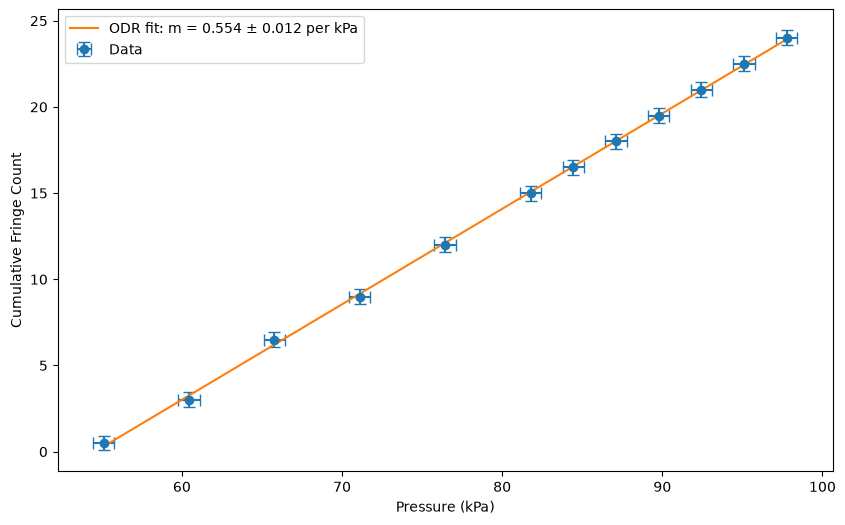

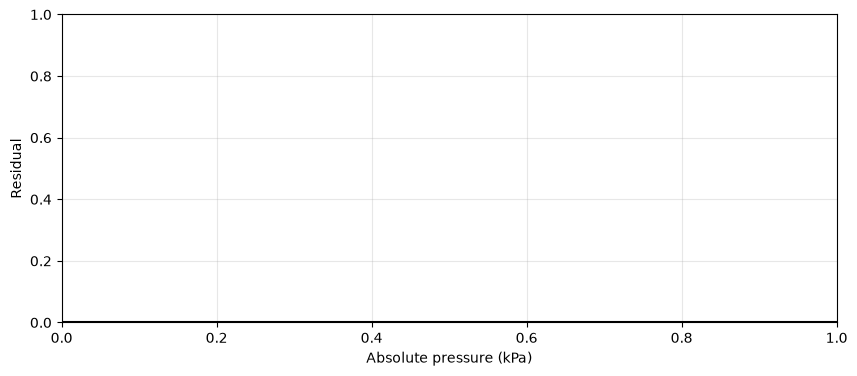

In [ ]:
# Create cumulative bins for each sweep
cumulative_bins = np.array([sum(sweep) for sweep in sweeps])
print(sweeps)
print(cumulative_bins)

# Calculate relevant uncertainties.
# Each sweep data point has a 0.25 uncertainty, independent of the values
sigma_bins = np.sqrt(0.25 ** 2 *3) # 3 measurements per sweep, add uncertainties in quadrature

# Add pressure uncertainties, which are 0.5 cm Hg for each measurement
sigma_pressure = 0.5 * 1.33322 # Convert to kPa

# Next, we can fit a linear model to the data to find the relationship between pressure and cumulative bins.
# Since we have uncertainties in both we use odr. 

def line(beta, pressure):
    return beta[0] * pressure + beta[1]

model = odr.Model(line)
data = odr.RealData(pressures, cumulative_bins, sx=sigma_pressure, sy=sigma_bins)
out = odr.ODR(data, model, beta0=[1.0, 0.0]).run()

m, b = out.beta
dm, db = np.sqrt(np.diag(out.cov_beta))

xx = np.linspace(pressures.min(), pressures.max(), 200)   # smooth x range for the line
yy = line(out.beta, xx)                      # same model function you gave ODR

plt.figure(figsize=(10, 6))
plt.errorbar(pressures, cumulative_bins, xerr=sigma_pressure, yerr=sigma_bins,
             fmt='o', capsize=4, label='Data')
plt.plot(xx, yy, label=f'ODR fit: m = {m:.3f} ± {dm:.3f} per kPa')
plt.legend()

# Add labels
plt.xlabel('Pressure (kPa)')
plt.ylabel('Cumulative Fringe Count')

# Add residuals
residuals = cumulative_bins - line(out.beta, pressures)
plt.figure(figsize=(10, 4))
plt.plot(pressures, residuals, 'o')
plt.axhline(0, color='k')
plt.xlabel('Absolute pressure (kPa)')
plt.ylabel('Residual')

plt.grid(alpha=0.3)
plt.show()